<a href="https://colab.research.google.com/github/Prasun6736/Natural_Language_Processing/blob/main/Negative_Sampling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [2]:
#1. corpus

corpus = [
    "I enjoy playing football",
    "I like reading books",
    "I love playing football with my friends",
    "I prefer reading books at home",
    "I enjoy playing sports",
    "I like studying",
    "I am passionate about football",
    "I enjoy reading"
]

In [3]:
sentences = [s.split() for s in corpus]

# --------------------------------------------------
# 2. Build vocabulary
# --------------------------------------------------

vocab = sorted(set(word for s in sentences for word in s))

word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_id.items()}

V = len(vocab)

print("Vocabulary:", vocab)

# --------------------------------------------------
# 3. Hyperparameters
# --------------------------------------------------

window = 1
d = 3
learning_rate = 0.05
epochs = 500

K = 3


Vocabulary: ['I', 'about', 'am', 'at', 'books', 'enjoy', 'football', 'friends', 'home', 'like', 'love', 'my', 'passionate', 'playing', 'prefer', 'reading', 'sports', 'studying', 'with']


In [5]:
# --------------------------------------------------
# 4. Generate center-context pairs
# --------------------------------------------------

pairs = []

for sentence in sentences:

    ids = [word_to_id[w] for w in sentence]

    for i, center in enumerate(ids):

        for j in range(
            max(0, i - window),
            min(len(ids), i + window + 1)
        ):

            if i != j:

                pairs.append(
                    (center, ids[j])
                )

print(
    "Number of positive pairs:",
    len(pairs)
)



Number of positive pairs: 56


In [6]:
# --------------------------------------------------
# 5. Initialize embeddings
# --------------------------------------------------

np.random.seed(42)

E = np.random.randn(V, d) * 0.1

W = np.random.randn(V, d) * 0.1

# --------------------------------------------------
# 6. Negative-sampling distribution
# --------------------------------------------------

counts = np.zeros(V)

for sentence in sentences:

    for word in sentence:

        counts[
            word_to_id[word]
        ] += 1

# P(w) proportional to frequency^0.75

neg_probs = counts ** 0.75

neg_probs = (
    neg_probs /
    neg_probs.sum()
)



In [7]:
# --------------------------------------------------
# 7. Sample negative words
# --------------------------------------------------

def sample_negatives(context, K):

    negatives = []

    while len(negatives) < K:

        word = np.random.choice(
            V,
            p=neg_probs
        )

        if word != context:

            negatives.append(word)

    return negatives

# --------------------------------------------------
# 8. Sigmoid
# --------------------------------------------------

def sigmoid(x):

    x = np.clip(
        x,
        -15,
        15
    )

    return (
        1.0 /
        (1.0 + np.exp(-x))
    )



In [8]:
# --------------------------------------------------
# 9. Train Skip-gram with Negative Sampling
# --------------------------------------------------

losses = []

for epoch in range(epochs):

    np.random.shuffle(pairs)

    total_loss = 0.0

    for center, context in pairs:

        # --------------------------------
        # Positive center-context pair
        # --------------------------------

        v = E[center].copy()

        u = W[context].copy()

        score = np.dot(v, u)

        # -log(sigmoid(score))
        total_loss += np.logaddexp(
            0.0,
            -score
        )

        grad_score = (
            sigmoid(score) - 1.0
        )

        grad_center = (
            grad_score * u
        )

        grad_context = (
            grad_score * v
        )

        E[center] -= (
            learning_rate *
            grad_center
        )

        W[context] -= (
            learning_rate *
            grad_context
        )

        # --------------------------------
        # Negative samples
        # --------------------------------

        negatives = sample_negatives(
            context,
            K
        )

        for neg in negatives:

            v = E[center].copy()

            u_neg = W[neg].copy()

            score_neg = np.dot(
                v,
                u_neg
            )

            # -log(sigmoid(-score))
            total_loss += np.logaddexp(
                0.0,
                score_neg
            )

            grad_score_neg = sigmoid(
                score_neg
            )

            grad_center = (
                grad_score_neg *
                u_neg
            )

            grad_negative = (
                grad_score_neg *
                v
            )

            E[center] -= (
                learning_rate *
                grad_center
            )

            W[neg] -= (
                learning_rate *
                grad_negative
            )

    losses.append(
        total_loss / len(pairs)
    )



In [9]:
# --------------------------------------------------
# 10. Print embeddings
# --------------------------------------------------

print("\nLearned embeddings:")

for word, idx in word_to_id.items():

    print(
        word,
        np.round(E[idx], 3)
    )



Learned embeddings:
I [ 2.719 -2.356  0.753]
about [ 2.139 -2.059 -2.945]
am [-0.29  -0.891 -1.31 ]
at [ 0.793 -3.036  2.401]
books [-0.778 -3.609 -5.184]
enjoy [-1.845 -2.403 -0.965]
football [-2.314 -4.057  1.458]
friends [ 1.859 -1.813 -3.23 ]
home [ 0.231 -2.261 -3.729]
like [-1.405 -1.789 -1.619]
love [-2.538 -3.232 -0.565]
my [-0.741 -3.317  1.998]
passionate [-0.346 -3.608  2.089]
playing [ 3.274 -2.068 -1.226]
prefer [-1.709 -2.729 -2.548]
reading [ 1.697 -2.444  1.66 ]
sports [-2.869 -4.113  0.485]
studying [ 2.449 -2.424  1.234]
with [ 2.64  -2.333 -3.574]


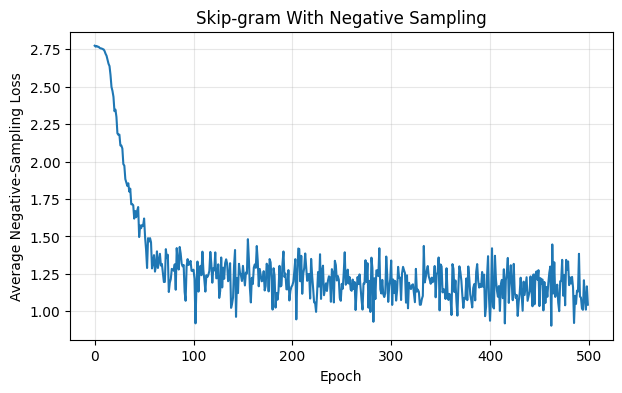

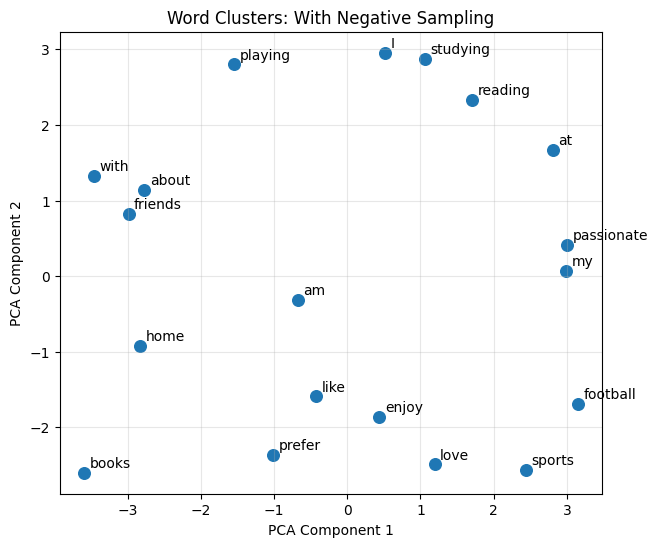

In [10]:
# --------------------------------------------------
# 11. Plot training loss
# --------------------------------------------------

plt.figure(figsize=(7, 4))

plt.plot(losses)

plt.xlabel("Epoch")

plt.ylabel(
    "Average Negative-Sampling Loss"
)

plt.title(
    "Skip-gram With Negative Sampling"
)

plt.grid(alpha=0.3)

plt.show()

# --------------------------------------------------
# 12. PCA visualization
# --------------------------------------------------

pca = PCA(n_components=2)

coords = pca.fit_transform(E)

plt.figure(figsize=(7, 6))

plt.scatter(
    coords[:, 0],
    coords[:, 1],
    s=70
)

for i, word in enumerate(vocab):

    plt.annotate(
        word,
        coords[i],
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")

plt.title(
    "Word Clusters: With Negative Sampling"
)

plt.grid(alpha=0.3)

plt.show()